# AlphaEarth embeddings & Overture Maps — Phase 1 briefing

**Repo:** [Kedar-V/Alpha-Earth-Embeddings-Research](https://github.com/Kedar-V/Alpha-Earth-Embeddings-Research)
**Purpose:** Meeting prep for building-type classification → carbon emissions estimation using AlphaEarth Foundations embeddings.

This notebook covers the two agenda items for the first Tuesday meeting:

1. **What embeddings are available, and across what geographies?**
2. **Can Overture Maps supply effective building-use labels** (especially residential vs non-residential)?

Live queries use the public Overture release `2026-08-19.0` via DuckDB + S3. AlphaEarth sections summarize the Earth Engine catalog and the [AlphaEarth Foundations paper](https://arxiv.org/abs/2507.22291).


## Setup

```bash
pip install -r requirements.txt
```

DuckDB reads Overture GeoParquet from the public AWS bucket (anonymous read of the published layout).
Run notebook cells from the **repo root** so `outputs/` lands next to this notebook's parent.


In [1]:
from __future__ import annotations

import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 80)

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
PLACES = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=places/type=place/*"

# Inner-city extracts (not full metro extents)
CITIES = {
    "Boston": (-71.18, 42.30, -71.02, 42.40),
    "Amsterdam": (4.85, 52.35, 4.95, 52.40),
    "Berlin": (13.35, 52.48, 13.50, 52.55),
    "Houston": (-95.45, 29.72, -95.30, 29.80),
    "Nairobi": (36.75, -1.35, 36.90, -1.25),
    "Lagos": (3.35, 6.45, 3.50, 6.55),
}

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET s3_region='us-west-2';")
con.execute("SET enable_progress_bar=false;")


def bbox_where(xmin, ymin, xmax, ymax) -> str:
    return (
        f"bbox.xmin > {xmin} AND bbox.xmax < {xmax} "
        f"AND bbox.ymin > {ymin} AND bbox.ymax < {ymax}"
    )


print("DuckDB ready · release", RELEASE)


DuckDB ready · release 2026-08-19.0


---

# 1. AlphaEarth embeddings

## Verdict for the meeting

**Global annual embeddings are available.** That is not a geography blocker for a planetary building-emissions pipeline.

| Property | Detail |
|---|---|
| **Product** | Satellite Embedding V1 (`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`) |
| **Producer** | AlphaEarth Foundations v2.1 (Google DeepMind + Earth Engine) |
| **Geography** | Terrestrial land + shallow/coastal water; poles limited (~±82°) |
| **Years** | Calendar years **2017–2024** |
| **Resolution** | **10 m**, local UTM tiles (~164 km side) |
| **Vector** | **64-D**, unit-length; year-consistent; linearly composable |
| **License** | CC-BY 4.0 (attribution required) |
| **Access** | [Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL); also `gs://alphaearth_foundations` (provider-pays) |
| **Weights** | **Not released** — consume precomputed embeddings only |

### Access options

1. **Annual Satellite Embeddings (recommended for Phase 1–3)** — global, public, ready.
2. **Custom Satellite Embeddings** — Google Maps Platform private preview; custom AOI / time windows; useful later for sub-annual change.
3. **Foundation model weights** — unavailable; we cannot fine-tune AlphaEarth itself.

### How embeddings are developed

Architecture: **Space Time Precision (STP)** — parallel ViT-like spatial attention, time-axial attention, and 3×3 convolutions; teacher–student training with an implicit decoder and Wikipedia/GBIF text alignment. Production variant ~**480M** parameters.

Training scale (paper / v2.0 base): ~**8.4M** year-length video sequences (~**3.0B** frames) from **5.1M** globally stratified 1.28 km sites. **v2.1** (public layers) added Antarctica samples and USDA **CDL** as an extra target (~**10.1M** sequences).

**Inference inputs** (required to generate embeddings):

| Modality | Sensor | Native res | Role |
|---|---|---|---|
| Optical | Sentinel-2 L1C (B2, B3, B4, B8, B11) | 10/20/60 m | input |
| Optical + thermal | Landsat 8/9 C2 T1 TOA | 15/30/100 m | input |
| C-band SAR | Sentinel-1 GRD IW | 10 m | input |

**Training targets only** (encoded into the latent, not needed at inference): ALOS-2 PALSAR-2, GEDI LiDAR, Copernicus GLO-30 DEM, ERA5-Land, GRACE, NLCD (US), CDL (v2.1), geocoded Wikipedia + GBIF text.

### Implications for building-type classification

- **10 m** is coarse for a small house (~1–4 pixels) but STP was trained on **1.28 km** chips → neighborhood context is baked in.
- Height / 3D is weak (DSM + sparse GEDI) → SF vs MF may lean on lot/street pattern more than roof geometry.
- Unit-length + year-consistent space → cosine / `1 − z_t · z_{t+Δt}` for change; mean-pool to parcel / block / neighborhood for context experiments.
- Eight annual layers (2017–2024) are enough to start the stretch **change-operator** work.

**Recommended Phase 2 setup:** use 2023 or 2024 annual layer; attach footprint-mean 64-D vector per building; also store mean-pooled embeddings at 50 m, 200 m, and 1 km.


### Optional: sample AlphaEarth vector in Earth Engine

```javascript
var dataset = ee.ImageCollection('GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL');
var point = ee.Geometry.Point([-71.0589, 42.3601]); // Boston
var image = dataset.filterDate('2024-01-01', '2025-01-01')
  .filterBounds(point).first();
print(image.reduceRegion({reducer: ee.Reducer.first(), geometry: point, scale: 10}));
```

Add a Python `earthengine-api` cell once GEE auth is configured for this environment.


---

# 2. Overture Maps — buildings as ground truth

## Schema

Overture buildings (~2.5–2.6B footprints, ODbL) conflate:

- OpenStreetMap (**highest priority**)
- Esri Community Maps / some cadastres
- Microsoft ML Buildings, Google Open Buildings, East Asia ML

Use attributes (optional):

- **`subtype`** — 13 broad current-use values: `residential`, `commercial`, `education`, `medical`, `industrial`, `civic`, `religious`, `transportation`, `outbuilding`, `service`, `entertainment`, `agricultural`, `military`
- **`class`** — ~80 finer types, usually OSM `building=*` (`house`, `apartments`, `school`, `hospital`, `office`, …)

Docs: [buildings guide](https://docs.overturemaps.org/guides/buildings/) · [BuildingSubtype](https://docs.overturemaps.org/schema/reference/buildings/types/building_subtype/) · [BuildingClass](https://docs.overturemaps.org/schema/reference/buildings/types/building_class/)


## 2.1 Label completeness by city extract

**Hypothesis:** labels exist globally via the schema.
**Observation:** use labels come almost entirely from OSM; ML footprints contribute **zero** subtype/class; even OSM is often `building=yes` (unlabeled).

The next cells re-query the public Overture release (network required; ~2–3 min total).


In [2]:
summaries = []
subtype_frames = []
source_frames = []

for name, (xmin, ymin, xmax, ymax) in CITIES.items():
    w = bbox_where(xmin, ymin, xmax, ymax)
    print(f"Querying buildings · {name} ...", flush=True)

    row = con.execute(
        f"SELECT COUNT(*)::BIGINT AS n, "
        f"COUNT(subtype)::BIGINT AS n_subtype, "
        f"COUNT(class)::BIGINT AS n_class, "
        f"COUNT(height)::BIGINT AS n_height, "
        f"COUNT(num_floors)::BIGINT AS n_floors "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) "
        f"WHERE {w}"
    ).fetchone()

    subtypes = con.execute(
        f"SELECT COALESCE(subtype, '(unlabeled)') AS subtype, COUNT(*)::BIGINT AS n "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) "
        f"WHERE {w} GROUP BY 1 ORDER BY n DESC"
    ).fetchdf()
    subtypes.insert(0, "city", name)
    subtype_frames.append(subtypes)

    sources = con.execute(
        f"SELECT COALESCE(sources[1].dataset, '(unknown)') AS src, "
        f"COUNT(*)::BIGINT AS n, COUNT(subtype)::BIGINT AS n_labeled "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) "
        f"WHERE {w} GROUP BY 1 ORDER BY n DESC"
    ).fetchdf()
    sources.insert(0, "city", name)
    source_frames.append(sources)

    n, n_sub, n_cls, n_h, n_f = row
    labeled = subtypes[subtypes["subtype"] != "(unlabeled)"]
    n_res = int(labeled.loc[labeled["subtype"] == "residential", "n"].sum()) if len(labeled) else 0
    summaries.append({
        "city": name,
        "n": int(n),
        "n_subtype": int(n_sub),
        "n_class": int(n_cls),
        "pct_labeled": 100.0 * n_sub / n if n else 0.0,
        "pct_height": 100.0 * n_h / n if n else 0.0,
        "pct_floors": 100.0 * n_f / n if n else 0.0,
        "n_residential": n_res,
        "pct_residential_of_labeled": 100.0 * n_res / n_sub if n_sub else 0.0,
    })

summary_df = pd.DataFrame(summaries)
subtype_df = pd.concat(subtype_frames, ignore_index=True)
source_df = pd.concat(source_frames, ignore_index=True)

summary_df.to_csv(OUT / "building_label_summary.csv", index=False)
subtype_df.to_csv(OUT / "building_subtypes_by_city.csv", index=False)
source_df.to_csv(OUT / "building_sources_by_city.csv", index=False)

summary_df.round(1)


Querying buildings · Boston ...
Querying buildings · Amsterdam ...
Querying buildings · Berlin ...
Querying buildings · Houston ...
Querying buildings · Nairobi ...
Querying buildings · Lagos ...


,city,n,n_subtype,n_class,pct_labeled,pct_height,pct_floors,n_residential,pct_residential_of_labeled
0,Boston,108701,23830,23242,21.9,94.0,10.3,18962,79.6
1,Amsterdam,75526,52653,52561,69.7,75.2,13.3,47653,90.5
2,Berlin,47315,35609,35405,75.3,23.2,68.6,27142,76.2
3,Houston,91891,14392,13869,15.7,91.0,1.8,11957,83.1
4,Nairobi,288829,5822,5496,2.0,0.1,1.0,3898,67.0
5,Lagos,151744,1426,1391,0.9,0.2,1.2,1166,81.8


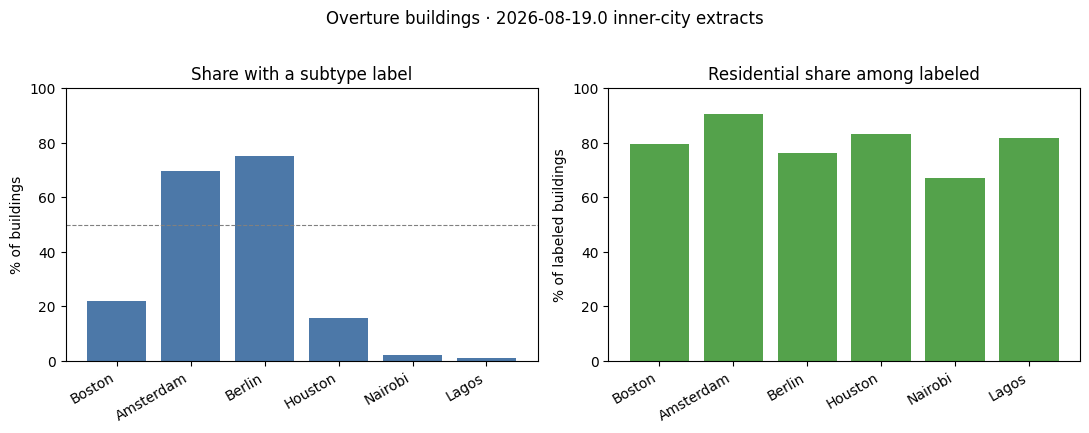

Saved: outputs/label_rates.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

cities = summary_df["city"].tolist()
x = range(len(cities))

axes[0].bar(x, summary_df["pct_labeled"], color="#4C78A8")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(cities, rotation=30, ha="right")
axes[0].set_ylabel("% of buildings")
axes[0].set_title("Share with a subtype label")
axes[0].set_ylim(0, 100)
axes[0].axhline(50, color="gray", ls="--", lw=0.8)

axes[1].bar(x, summary_df["pct_residential_of_labeled"], color="#54A24B")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(cities, rotation=30, ha="right")
axes[1].set_ylabel("% of labeled buildings")
axes[1].set_title("Residential share among labeled")
axes[1].set_ylim(0, 100)

fig.suptitle(f"Overture buildings · {RELEASE} inner-city extracts", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "label_rates.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", OUT / "label_rates.png")


## 2.2 Sources: footprints vs labels

ML footprints expand coverage (especially Global South) but **never** carry use labels in these extracts.


In [4]:
source_pivot = (
    source_df.pivot_table(index="city", columns="src", values="n", aggfunc="sum", fill_value=0)
    .reindex(cities)
)
source_labeled = (
    source_df.pivot_table(index="city", columns="src", values="n_labeled", aggfunc="sum", fill_value=0)
    .reindex(cities)
)

display(source_pivot)
print("\nLabeled counts by source (expect ~0 for Microsoft / Google / Esri):")
display(source_labeled)


src,Esri Community Maps,Google Open Buildings,Microsoft ML Buildings,OpenStreetMap
city,,,,
Boston,1138,0,1445,106118
Amsterdam,0,0,509,75017
Berlin,0,0,1998,45317
Houston,0,0,2406,89485
Nairobi,0,70630,13088,205111
Lagos,0,38834,4541,108369



Labeled counts by source (expect ~0 for Microsoft / Google / Esri):


src,Esri Community Maps,Google Open Buildings,Microsoft ML Buildings,OpenStreetMap
city,,,,
Boston,0,0,0,23830
Amsterdam,0,0,0,52653
Berlin,0,0,0,35609
Houston,0,0,0,14392
Nairobi,0,0,0,5822
Lagos,0,0,0,1426


## 2.3 Subtype distribution (residential vs non-residential)

When subtype is present, the split is **schema-clean**: `residential` is a first-class bucket; non-residential is the mutually exclusive leftover. The problem is **missingness**, not ambiguous subtype values.


In [5]:
subtype_wide = subtype_df.pivot_table(
    index="subtype", columns="city", values="n", aggfunc="sum", fill_value=0
)
pct_of_city = subtype_wide.div(summary_df.set_index("city")["n"], axis=1) * 100
display(pct_of_city.round(2).sort_values(by=cities[0], ascending=False))

labeled_only = subtype_df[subtype_df["subtype"] != "(unlabeled)"].copy()
labeled_totals = labeled_only.groupby("city")["n"].sum()
labeled_pct = (
    labeled_only.pivot_table(index="subtype", columns="city", values="n", aggfunc="sum", fill_value=0)
    .div(labeled_totals, axis=1)
    * 100
)
print("\n% of LABELED buildings by subtype:")
display(labeled_pct.round(1).sort_values(by=cities[0], ascending=False))


city,Amsterdam,Berlin,Boston,Houston,Lagos,Nairobi
subtype,,,,,,
(unlabeled),30.28,24.74,78.08,84.34,99.06,97.98
residential,63.09,57.36,17.44,13.01,0.77,1.35
commercial,2.90,6.68,1.95,1.04,0.05,0.18
education,0.25,1.87,0.83,0.17,0.00,0.08
outbuilding,1.46,4.24,0.41,0.74,0.03,0.03
religious,0.09,0.39,0.29,0.14,0.02,0.05
civic,0.07,1.02,0.27,0.18,0.00,0.03
transportation,0.06,0.33,0.19,0.21,0.00,0.01
industrial,1.43,1.19,0.18,0.05,0.04,0.22



% of LABELED buildings by subtype:


city,Amsterdam,Berlin,Boston,Houston,Lagos,Nairobi
subtype,,,,,,
residential,90.5,76.2,79.6,83.1,81.8,67.0
commercial,4.2,8.9,8.9,6.7,5.8,9.1
education,0.4,2.5,3.8,1.1,0.4,4.2
outbuilding,2.1,5.6,1.9,4.7,3.6,1.5
religious,0.1,0.5,1.3,0.9,2.4,2.6
civic,0.1,1.4,1.2,1.1,0.5,1.7
transportation,0.1,0.4,0.9,1.4,0.5,0.5
industrial,2.0,1.6,0.8,0.3,4.3,10.9
service,0.4,1.6,0.6,0.1,0.0,0.0


## 2.4 Study taxonomy vs Overture `class`

Map the paper's functional categories onto Overture classes and count high-precision labels per extract.


In [6]:
STUDY_CLASSES = [
    "house", "detached", "bungalow", "semi", "semidetached_house", "terrace",
    "apartments", "dormitory", "residential",
    "school", "kindergarten", "college", "university",
    "hospital",
    "office", "commercial", "retail", "hotel", "supermarket",
    "industrial", "warehouse", "factory",
]

class_frames = []
quoted = ", ".join(repr(c) for c in STUDY_CLASSES)
for name, (xmin, ymin, xmax, ymax) in CITIES.items():
    w = bbox_where(xmin, ymin, xmax, ymax)
    print(f"Class counts · {name} ...", flush=True)
    df = con.execute(
        f"SELECT class, COUNT(*)::BIGINT AS n "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) "
        f"WHERE {w} AND class IN ({quoted}) "
        f"GROUP BY 1 ORDER BY n DESC"
    ).fetchdf()
    df.insert(0, "city", name)
    class_frames.append(df)

class_df = pd.concat(class_frames, ignore_index=True)
class_df.to_csv(OUT / "study_class_counts.csv", index=False)

class_wide = class_df.pivot_table(
    index="class", columns="city", values="n", aggfunc="sum", fill_value=0
)
order = [c for c in STUDY_CLASSES if c in class_wide.index]
class_wide = class_wide.reindex(order)
class_wide


Class counts · Boston ...
Class counts · Amsterdam ...
Class counts · Berlin ...
Class counts · Houston ...
Class counts · Nairobi ...
Class counts · Lagos ...


city,Amsterdam,Berlin,Boston,Houston,Lagos,Nairobi
class,,,,,,
house,10115,883,2707,8821,214,1748
detached,3,219,3228,748,0,77
bungalow,0,416,4,0,0,1
semidetached_house,1,34,1321,21,1,2
terrace,3,360,479,125,0,12
apartments,35587,20785,8962,379,39,1285
dormitory,0,46,312,5,6,47
residential,5,3163,823,1169,905,706
school,149,536,199,123,5,182


In [7]:
ROLLUP = {
    "single_family_like": ["house", "detached", "bungalow", "semi", "semidetached_house"],
    "terrace_ambiguous": ["terrace"],
    "multi_family": ["apartments", "dormitory"],
    "residential_generic": ["residential"],
    "education": ["school", "kindergarten", "college", "university"],
    "hospital": ["hospital"],
    "commercial_office": ["office", "commercial", "retail", "hotel", "supermarket"],
    "industrial": ["industrial", "warehouse", "factory"],
}

rows = []
for city in cities:
    r = {"city": city}
    for label, members in ROLLUP.items():
        present = [m for m in members if m in class_wide.index]
        r[label] = int(class_wide.loc[present, city].sum()) if present else 0
    rows.append(r)

rollup_df = pd.DataFrame(rows).set_index("city")
rollup_df.to_csv(OUT / "study_taxonomy_rollup.csv")
rollup_df


,single_family_like,terrace_ambiguous,multi_family,residential_generic,education,hospital,commercial_office,industrial
city,,,,,,,,
Boston,7260,479,9274,823,856,92,1892,271
Amsterdam,10119,3,35587,5,179,5,2167,1081
Berlin,1552,360,20831,3163,878,148,2975,654
Houston,9590,125,384,1169,149,9,629,75
Nairobi,1828,12,1332,706,225,60,404,674
Lagos,215,0,45,905,6,2,79,61


### Clarity assessment

| Study class | Overture mapping | Clarity |
|---|---|---|
| Single-family | `house`, `detached`, `bungalow`, `semi`, `semidetached_house` | **Clear** when those classes are set |
| Multi-family | `apartments` (+ `dormitory` as institutional-residential) | **Clear** for apartments |
| Generic residential / terrace | `class=residential`, `terrace` | **Ambiguous** for SF vs MF |
| Schools | `subtype=education` / `school`, `kindergarten`, `college`, `university` | **High precision, low recall** |
| Hospitals | `subtype=medical` / `hospital` | **High precision, low recall** |
| Commercial / office | `office`, `retail`, `hotel`, `commercial` | **Muddy** for energy archetypes |

**Never treat unlabeled footprints as negatives.**


## 2.5 Places theme — denser institutional signals

Building `class=school` / `class=hospital` is sparse outside well-mapped Europe. Overture **Places** often has many more school/hospital points. A spatial join is a natural **noisy GT** path — campuses and mixed-use will collide.


In [8]:
place_rows = []
for name, (xmin, ymin, xmax, ymax) in CITIES.items():
    w = (
        f"bbox.xmin BETWEEN {xmin} AND {xmax} "
        f"AND bbox.ymin BETWEEN {ymin} AND {ymax}"
    )
    print(f"Places · {name} ...", flush=True)
    inst = con.execute(
        f"SELECT "
        f"COUNT(*)::BIGINT AS n_places, "
        f"SUM(CASE WHEN taxonomy.hierarchy[1]='education' THEN 1 ELSE 0 END)::BIGINT AS education_l0, "
        f"SUM(CASE WHEN taxonomy.hierarchy[1]='health_care' THEN 1 ELSE 0 END)::BIGINT AS health_l0, "
        f"SUM(CASE WHEN basic_category IN ('school','elementary_school','high_school','middle_school','preschool') "
        f"OR taxonomy.primary IN ('school','elementary_school','high_school','middle_school') "
        f"THEN 1 ELSE 0 END)::BIGINT AS schools, "
        f"SUM(CASE WHEN basic_category IN ('hospital','medical_center') "
        f"OR taxonomy.primary IN ('hospital','medical_center') "
        f"THEN 1 ELSE 0 END)::BIGINT AS hospitals, "
        f"SUM(CASE WHEN basic_category IN ('college_university','university') "
        f"OR taxonomy.primary IN ('college_university','university') "
        f"THEN 1 ELSE 0 END)::BIGINT AS universities, "
        f"SUM(CASE WHEN taxonomy.hierarchy[1]='services_and_business' THEN 1 ELSE 0 END)::BIGINT AS business "
        f"FROM read_parquet('{PLACES}', hive_partitioning=1) WHERE {w}"
    ).fetchone()
    place_rows.append({
        "city": name,
        "n_places": inst[0],
        "education_l0": inst[1],
        "health_l0": inst[2],
        "school_pois": inst[3],
        "hospital_pois": inst[4],
        "university_pois": inst[5],
        "business_l0": inst[6],
    })

places_df = pd.DataFrame(place_rows)
places_df.to_csv(OUT / "places_institutional_counts.csv", index=False)

compare = places_df.set_index("city").copy()
compare["school_buildings"] = [
    int(class_wide.loc["school", c]) if "school" in class_wide.index else 0 for c in cities
]
compare["hospital_buildings"] = [
    int(class_wide.loc["hospital", c]) if "hospital" in class_wide.index else 0 for c in cities
]
compare[
    [
        "school_buildings",
        "school_pois",
        "hospital_buildings",
        "hospital_pois",
        "education_l0",
        "health_l0",
    ]
]


Places · Boston ...
Places · Amsterdam ...
Places · Berlin ...
Places · Houston ...
Places · Nairobi ...
Places · Lagos ...


,school_buildings,school_pois,hospital_buildings,hospital_pois,education_l0,health_l0
city,,,,,,
Boston,199,502,92,399,2550,7280
Amsterdam,149,295,5,29,990,1014
Berlin,536,540,148,99,2016,2440
Houston,123,213,9,48,809,2856
Nairobi,182,677,60,363,1666,1197
Lagos,5,447,2,95,1017,338


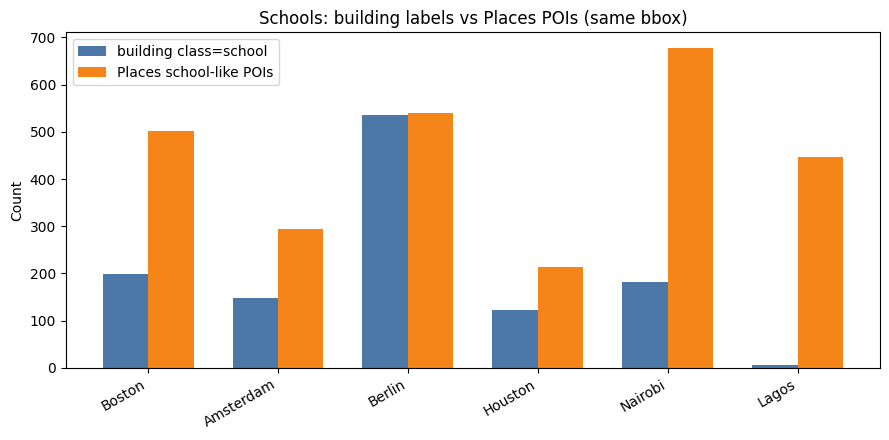

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
idx = range(len(cities))
width = 0.35
ax.bar(
    [i - width / 2 for i in idx],
    compare["school_buildings"],
    width,
    label="building class=school",
    color="#4C78A8",
)
ax.bar(
    [i + width / 2 for i in idx],
    compare["school_pois"],
    width,
    label="Places school-like POIs",
    color="#F58518",
)
ax.set_xticks(list(idx))
ax.set_xticklabels(cities, rotation=30, ha="right")
ax.set_ylabel("Count")
ax.set_title("Schools: building labels vs Places POIs (same bbox)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "schools_buildings_vs_places.png", dpi=150, bbox_inches="tight")
plt.show()


---

# 3. Recommended label stack for the study

| Layer | Role | Geography | Noise |
|---|---|---|---|
| Overture `class ∈ {house, detached, apartments, school, hospital, office}` | High-precision core GT | Strong in Europe / well-mapped US cores; thin in Lagos/Nairobi | Low |
| `subtype=residential` vs other labeled subtypes | Binary residential task / pretraining | Same | Low on labeled rows; missingness is the issue |
| Places → building spatial join (school, hospital, university, office) | Noisy positives to raise recall | Better Global South coverage | Medium–high |
| [GHS-OBAT](https://gee-community-catalog.org/projects/ghs_obat/) residential/non-residential on ~2.3B Overture footprints | Global weak binary labels | Nearly global | High (RS-derived, ~2020) |
| Unlabeled footprints | **Do not treat as negatives** | Majority of the map | Unknown |

### Tuesday talking points

1. **AlphaEarth is globally available** at 10 m for 2017–2024. Plan around public annual layers; Custom Embeddings are optional later.
2. **Overture schema supports the taxonomy**, but fill rate does not — build the core classifier on OSM-class buildings in well-mapped cities, then test geographic generalization with Places joins / GHS-OBAT.
3. **SF vs MF is the cut to watch** — clean for `house`/`detached` vs `apartments`, messy for generic `residential` and `terrace`. Budget stratified QA; that distinction drives energy intensity.


In [10]:
brief = {
    "overture_release": RELEASE,
    "cities": {k: list(v) for k, v in CITIES.items()},
    "alphaearth": {
        "collection": "GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL",
        "years": list(range(2017, 2025)),
        "resolution_m": 10,
        "dims": 64,
        "coverage": "global land + shallow/coastal water",
        "license": "CC-BY 4.0",
        "weights_released": False,
    },
    "building_summary": summary_df.to_dict(orient="records"),
    "rollup": rollup_df.reset_index().to_dict(orient="records"),
    "places": places_df.to_dict(orient="records"),
}
path = OUT / "phase1_briefing_snapshot.json"
path.write_text(json.dumps(brief, indent=2))
print("Wrote", path)
print("\nOutputs directory:")
for p in sorted(OUT.iterdir()):
    print(" ", p.name, f"({p.stat().st_size} bytes)")


Wrote outputs/phase1_briefing_snapshot.json

Outputs directory:
  building_label_summary.csv (731 bytes)
  building_sources_by_city.csv (558 bytes)
  building_subtypes_by_city.csv (1745 bytes)
  label_rates.png (63173 bytes)
  phase1_briefing_snapshot.json (5713 bytes)
  places_institutional_counts.csv (331 bytes)
  schools_buildings_vs_places.png (55218 bytes)
  study_class_counts.csv (2301 bytes)
  study_taxonomy_rollup.csv (358 bytes)


## References

- [Satellite Embedding V1 — Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL)
- Brown et al., 2025. *AlphaEarth Foundations*. [arXiv:2507.22291](https://arxiv.org/abs/2507.22291)
- [DeepMind AlphaEarth blog](https://deepmind.google/blog/alphaearth-foundations-helps-map-our-planet-in-unprecedented-detail/)
- [Overture Maps](https://overturemaps.org/) · [Buildings guide](https://docs.overturemaps.org/guides/buildings/) · [DuckDB access](https://docs.overturemaps.org/getting-data/duckdb/)
- [GHS-OBAT](https://gee-community-catalog.org/projects/ghs_obat/) — optional global residential/non-residential attributes on Overture footprints
